# Groups of nodes: E. coli protein complexes

Nodes are proteins, edges are high-confidence interactions (STRING v12, score ≥ 700), and a
filled simplex is a set of proteins that interact pairwise **and** belong to the same annotated
complex (EMBL-EBI Complex Portal). The question: does HHO pull the members of each complex
together? The notebook colors the proteins by functional category, reads the markers, recovers
complex partners, and measures how much tighter each complex gets.

Node colors are COG functional categories (NCBI COG 2020). Without a cached copy, the first run
downloads STRING's all-organism COG table (about 750 MB, streamed; only the E. coli lines are
kept, about 1 MB), which can take a few minutes.

The files are downloaded and cached on first use, or read from `HOHYPEMB_SNAPSHOT_DIR`. The
Complex Portal file is a moving release: without the snapshot used for the paper (see the
README), the counts may differ slightly.

In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

sys.path.insert(0, "..")  # finds hohypemb/ in the repository; not needed if you copied or installed it
import hohypemb as hh
from hohypemb.datasets.ecoli import load_ecoli

sc, complexes = load_ecoli(max_nodes=300, with_cog=True, return_complexes=True,
                           data_dir=os.environ.get("HOHYPEMB_SNAPSHOT_DIR"))
sc = sc.giant_component()
print(sc.n_nodes, "proteins,", sc.one_skeleton.number_of_edges(), "interactions,",
      len(sc.filled_triangles()), "filled and", len(sc.empty_triangles()), "empty triangles")

286 proteins, 5027 interactions, 5366 filled and 69552 empty triangles


## 1. Embed and plot

Each protein is colored by its COG functional category. Categories are ordered by decreasing
number of proteins in the network; "Unknown category" (no COG annotation) is gray.

Here the complex is used in dimension 2: every triangle of interacting proteins that lie inside an
annotated complex is a filled 2-simplex, and HHO (`layer2="all_simplices"`, `max_dim=2`) gives each
of them its own point in the disk, in addition to the points of the proteins. That is 5,366
triangle points on top of the protein points, so the HHO fit below takes about a minute and about
1 GB of memory. The classical fit is unchanged.

18 categories and 11 proteins with an unknown category, among 286 proteins
Translation, ribosomal structure and biogenesis                  84
Amino acid transport and metabolism                              54
Carbohydrate transport and metabolism                            32
Posttranslational modification, protein turnover, chaperones     31
Coenzyme transport and metabolism                                15
Transcription                                                    13
Unknown category                                                 11
Replication, recombination and repair                             8
Intracellular trafficking, secretion, and vesicular transport     7
Energy production and conversion                                  6
Nucleotide transport and metabolism                               5
Inorganic ion transport and metabolism                            5
Signal transduction mechanisms                                    4
Defense mechanisms                       

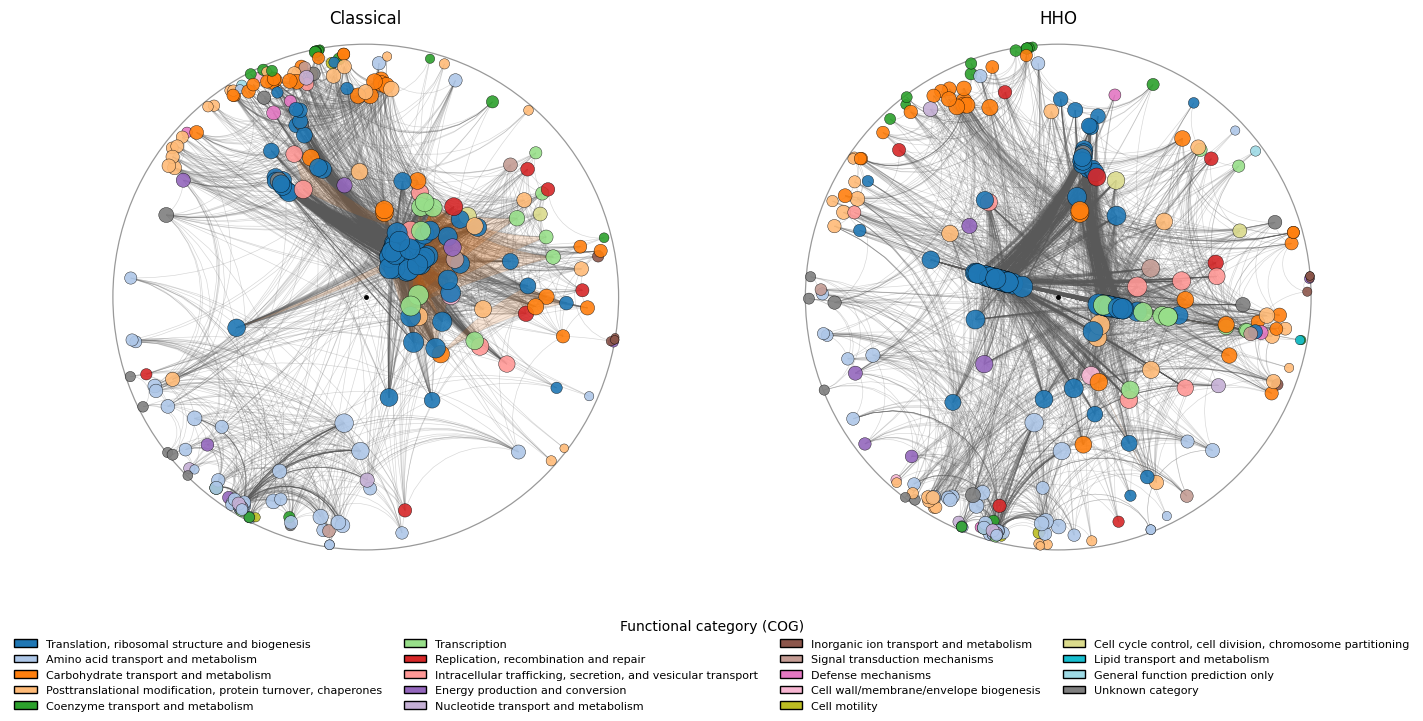

In [2]:
PARAMS = hh.presets.EMBEDDING_PARAMS["ecoli"]
classical = hh.ClassicalEmbedder(**PARAMS).fit(sc, seed=0)
warnings.filterwarnings("ignore", message="Embedding .* dense matrices")  # memory cost stated above
hho = hh.HHOEmbedder(mu=15, gamma=0.5, layer2="all_simplices", max_dim=2, **PARAMS).fit(sc, seed=0)

counts = pd.Series(sc.node_labels).value_counts()
categories = [c for c in counts.index if c != "Unknown category"]
grays = plt.get_cmap("tab20").colors[14:16]  # kept for "Unknown category" only
tab = [c for c in plt.get_cmap("tab20").colors + plt.get_cmap("tab20b").colors if c not in grays]
cog_colors = dict(zip(categories, tab))
cog_colors["Unknown category"] = "#7f7f7f"
print(len(categories), "categories and", counts.get("Unknown category", 0), "proteins with an unknown category,",
      "among", sc.n_nodes, "proteins")
print(counts.to_string())

NODE_SCALE = 2.5  # larger markers, so that the proteins stay visible in a 14 x 7 in figure
fig = hh.plotting.plot_comparison(sc, classical, hho, node_colors=[cog_colors[c] for c in sc.node_labels],
                                  legend=cog_colors, node_scale=NODE_SCALE, figsize=(14, 7))
fig.legends[0].set_title("Functional category (COG)")
fig.subplots_adjust(bottom=0.22)
plt.show()

*What to expect:* the two panels show the same proteins and the same interactions (gray edges) in
the classical and the HHO embedding, so the layouts can be compared directly. The printed counts
give the number of proteins per category. The figure shows how the categories are spread over the
disk in each embedding; the case studies in section 4 look at protein complexes instead.

## 2. Markers

(A) area ratio HHO / classical of the filled triangles, (B) filled vs empty triangles under HHO,
(C) embedding distance against hop distance.

*What to expect:* HHO shrinks the filled triangles, and the direction of this result is robust.
Its size is not: under HHO many filled triangles end up with an area below 1e-6, at the
numerical floor of the area formula, so do not read much into the magnitude of the ratio. The
printed lines give the median ratio (about 8e-4), the share of filled triangles that shrink
(99.7%), the share below 1e-6 (42%) and the distortion correlation (0.71 classical, 0.68 HHO:
HHO preserves the graph distances about as well as the classical embedding, slightly less well).
The same holds for the filled-vs-empty fold printed below (about 6,800): its denominator is a
filled-triangle area at the numerical floor.

median area ratio 7.9e-04; 99.7% of filled triangles shrink
42% of filled triangles have |area| < 1e-6 under HHO
under HHO, empty triangles are 6,831x larger than filled ones
distortion Spearman rho: classical 0.71, HHO 0.68


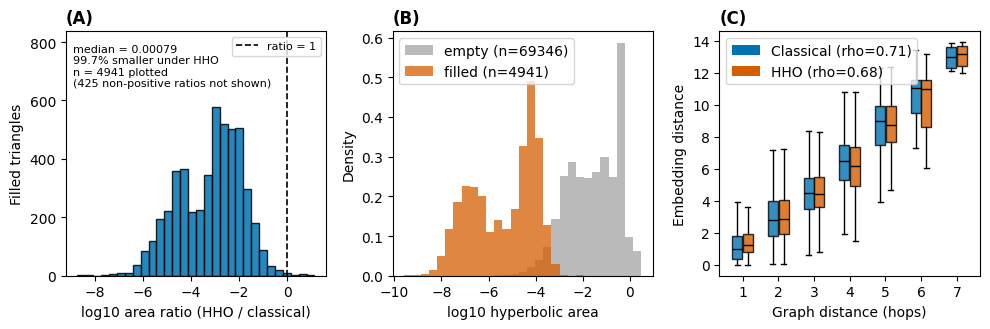

In [3]:
area = hh.markers.area_ratio(sc, classical, hho)
surf = hh.markers.surface_vs_empty_areas(sc, hho)
dist_cl = hh.markers.global_distortion(sc, classical)
dist_hho = hh.markers.global_distortion(sc, hho)
print(f"median area ratio {area.median_ratio:.1e}; {100 * area.frac_below_1:.1f}% of filled triangles shrink")
print(f"{np.mean(np.abs(area.area_hho) < 1e-6):.0%} of filled triangles have |area| < 1e-6 under HHO")
print(f"under HHO, empty triangles are {surf.fold:,.0f}x larger than filled ones")
print(f"distortion Spearman rho: classical {dist_cl.spearman_rho:.2f}, HHO {dist_hho.spearman_rho:.2f}")
fig = hh.plotting.plot_synthesis(area, surf, dist_cl, dist_hho)
plt.show()

## 3. Recover complex partners

For each protein with at least one partner (another member of one of its complexes) in the
network: which fraction of its 5 nearest neighbors in the embedding are partners?

70 proteins; mean precision@5: classical 0.374, HHO 0.711 (paired Wilcoxon p = 6.7e-10)


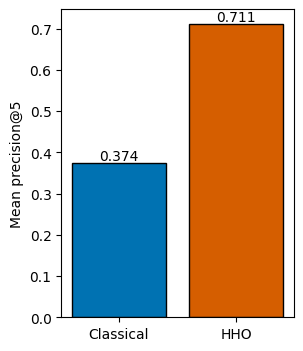

In [4]:
groups = [g for g in (sc.indices_of(m) for m in complexes.values()) if len(g) >= 2]
prec_cl = hh.markers.partner_precision_at_k(sc, classical, k=5, groups=groups)
prec_hho = hh.markers.partner_precision_at_k(sc, hho, k=5, groups=groups)
differs = np.any(prec_hho.precision != prec_cl.precision)
p = wilcoxon(prec_hho.precision, prec_cl.precision).pvalue if differs else float("nan")
print(f"{len(prec_hho.eligible)} proteins; mean precision@5: classical {prec_cl.mean:.3f}, "
      f"HHO {prec_hho.mean:.3f} (paired Wilcoxon p = {p:.1e})")
fig, ax = plt.subplots(figsize=(3, 4))
hh.plotting.plot_partner_precision(ax, prec_cl, prec_hho)
plt.show()

*What to expect:* the mean precision@5 is about 0.37 for the classical embedding and 0.71 for HHO,
over the 70 eligible proteins, and the paired test gives p of about 7e-10.

## 4. How much tighter is each complex?

The helper picks the best-covered complexes (up to six). A complex is skipped when its Jaccard
index (shared members / all members of the pair) with an already chosen complex exceeds 0.3, so the
chosen ones are distinct; five qualify. For each complex, the table gives the mean hyperbolic
distance between its members, in each embedding.

In [5]:
def pick_case_studies(complexes, sc, n=6, min_members=3, max_jaccard=0.3):
    # Greedy: largest coverage in the network first (ties broken by name), skipping near-duplicates.
    coverage = sorted(((name, set(sc.indices_of(m))) for name, m in complexes.items()),
                      key=lambda t: (-len(t[1]), t[0]))
    chosen = []
    for name, members in coverage:
        if len(members) < min_members:
            continue
        if all(len(members & s) / len(members | s) <= max_jaccard for _, s in chosen):
            chosen.append((name, members))
        if len(chosen) >= n:
            break
    return chosen


cases = pick_case_studies(complexes, sc)
members = [sorted(m) for _, m in cases]
compact = pd.DataFrame({
    "complex": [name for name, _ in cases],
    "members": [len(m) for m in members],
    "mean distance, classical": hh.markers.group_compactness(classical, members),
    "mean distance, HHO": hh.markers.group_compactness(hho, members),
})
compact["tighter under HHO"] = compact["mean distance, classical"] / compact["mean distance, HHO"]
compact.round(3)

,complex,members,"mean distance, classical","mean distance, HHO",tighter under HHO
0,50S large ribosomal subunit,31,0.361,0.145,2.482
1,30S small ribosomal subunit,18,0.192,0.093,2.058
2,Transcription elongation complex,7,0.473,0.314,1.507
3,Holo-translocon SecYEG-SecDF-YajC-YidC complex,3,0.955,0.558,1.710
4,RNA degradosome,3,1.186,0.921,1.288


*What to expect:* the table has one row per chosen complex, and in each row the mean distance is
smaller under HHO than in the classical embedding (ratios from about 1.3 to 2.5).